In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn.preprocessing
import sklearn.model_selection

In [3]:
df = pd.read_csv('loan_approval_dataset.csv')

In [4]:
df.sample(10)

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
2669,2670,5,Graduate,Yes,9500000,36700000,16,348,3500000,2200000,31600000,11400000,Rejected
2146,2147,3,Not Graduate,No,7400000,23400000,16,700,19300000,3000000,20700000,8900000,Approved
510,511,1,Not Graduate,Yes,3200000,9000000,20,372,2700000,2800000,7200000,3800000,Rejected
2777,2778,5,Graduate,Yes,8800000,21300000,14,852,8000000,6400000,28500000,9900000,Approved
2652,2653,2,Graduate,Yes,7000000,18900000,8,584,13000000,13600000,20600000,5000000,Approved
2550,2551,1,Graduate,No,7400000,19200000,20,415,2200000,4800000,29200000,7000000,Rejected
2462,2463,0,Not Graduate,Yes,8200000,31500000,8,403,11500000,8800000,19000000,6100000,Rejected
109,110,2,Graduate,No,3300000,6800000,14,317,3400000,300000,11700000,3600000,Rejected
940,941,5,Graduate,Yes,7600000,20000000,10,522,21500000,1400000,20400000,4300000,Rejected
291,292,1,Graduate,Yes,5800000,19500000,20,431,13800000,5000000,15600000,3300000,Rejected


In [5]:
df.shape

(4269, 13)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 531.6 KB


In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_id,4269.0,NaN,NaN,NaN,2135.0,1232.498479,1.0,1068.0,2135.0,3202.0,4269.0
no_of_dependents,4269.0,NaN,NaN,NaN,2.498712,1.69591,0.0,1.0,3.0,4.0,5.0
education,4269,2,Graduate,2144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
self_employed,4269,2,Yes,2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_annum,4269.0,NaN,NaN,NaN,5059123.916608,2806839.831818,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,NaN,NaN,NaN,15133450.456781,9043362.984843,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,NaN,NaN,NaN,10.900445,5.709187,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,NaN,NaN,NaN,599.936051,172.430401,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,NaN,NaN,NaN,7472616.537831,6503636.587664,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,NaN,NaN,NaN,4973155.305692,4388966.089638,0.0,1300000.0,3700000.0,7600000.0,19400000.0


In [8]:
df = df.drop_duplicates()

In [9]:
df.isnull().mean()*100

loan_id                      0.0
 no_of_dependents            0.0
 education                   0.0
 self_employed               0.0
 income_annum                0.0
 loan_amount                 0.0
 loan_term                   0.0
 cibil_score                 0.0
 residential_assets_value    0.0
 commercial_assets_value     0.0
 luxury_assets_value         0.0
 bank_asset_value            0.0
 loan_status                 0.0
dtype: float64

In [10]:
df.isna().mean()*100

loan_id                      0.0
 no_of_dependents            0.0
 education                   0.0
 self_employed               0.0
 income_annum                0.0
 loan_amount                 0.0
 loan_term                   0.0
 cibil_score                 0.0
 residential_assets_value    0.0
 commercial_assets_value     0.0
 luxury_assets_value         0.0
 bank_asset_value            0.0
 loan_status                 0.0
dtype: float64

In [11]:
df.columns.tolist()

['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

In [12]:
df.columns = df.columns.str.strip()

In [13]:
df = df.drop(columns='loan_id')

In [14]:
df['loan_status'].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [15]:
df['loan_status'] = df['loan_status'].str.strip().map({'Approved':1, 'Rejected':0})

In [16]:
X = df.drop(columns = 'loan_status').copy()
y = df['loan_status'].copy()

In [17]:
X.sample(10)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
3261,0,Not Graduate,Yes,2800000,6300000,12,647,4100000,0,8700000,2300000
2449,5,Graduate,Yes,5200000,12700000,16,718,11700000,100000,18100000,7200000
4108,3,Not Graduate,Yes,9200000,23200000,8,380,13100000,15500000,18900000,6100000
3658,2,Graduate,No,600000,1300000,12,475,100000,1100000,2300000,600000
378,2,Not Graduate,Yes,5000000,17600000,20,465,6200000,5200000,16500000,5200000
396,0,Graduate,No,600000,1700000,2,621,400000,400000,2000000,200000
1395,4,Graduate,No,4700000,13100000,14,492,1000000,4500000,14100000,6400000
531,4,Not Graduate,Yes,300000,1000000,20,655,0,100000,1100000,400000
1812,5,Not Graduate,No,9000000,35200000,2,437,18400000,17800000,18300000,10400000
953,5,Graduate,Yes,8700000,28100000,10,660,25500000,800000,25900000,10100000


In [18]:
X['education'] = X['education'].str.strip().map({'Graduate':1, 'Not Graduate':0})
X['self_employed'] = X['self_employed'].str.strip().map({'Yes':1, 'No':0})

In [19]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   no_of_dependents          4269 non-null   int64
 1   education                 4269 non-null   int64
 2   self_employed             4269 non-null   int64
 3   income_annum              4269 non-null   int64
 4   loan_amount               4269 non-null   int64
 5   loan_term                 4269 non-null   int64
 6   cibil_score               4269 non-null   int64
 7   residential_assets_value  4269 non-null   int64
 8   commercial_assets_value   4269 non-null   int64
 9   luxury_assets_value       4269 non-null   int64
 10  bank_asset_value          4269 non-null   int64
dtypes: int64(11)
memory usage: 367.0 KB


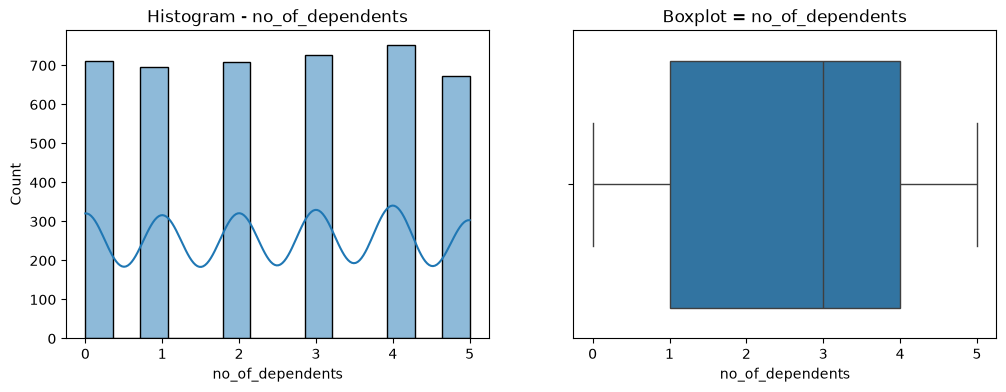

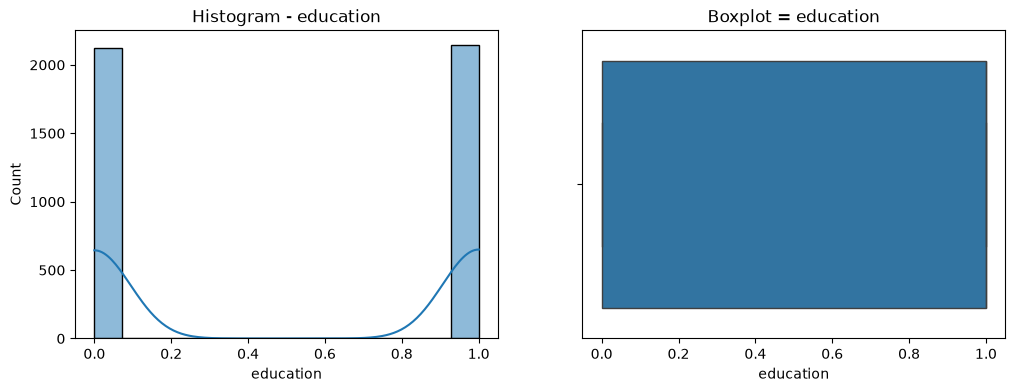

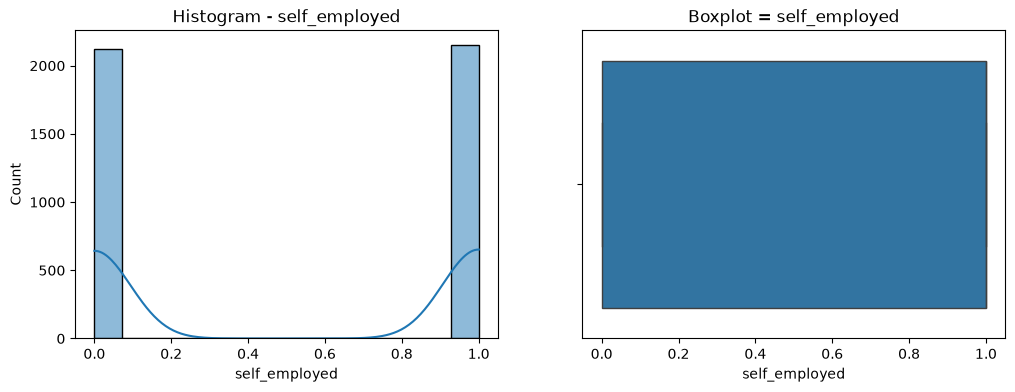

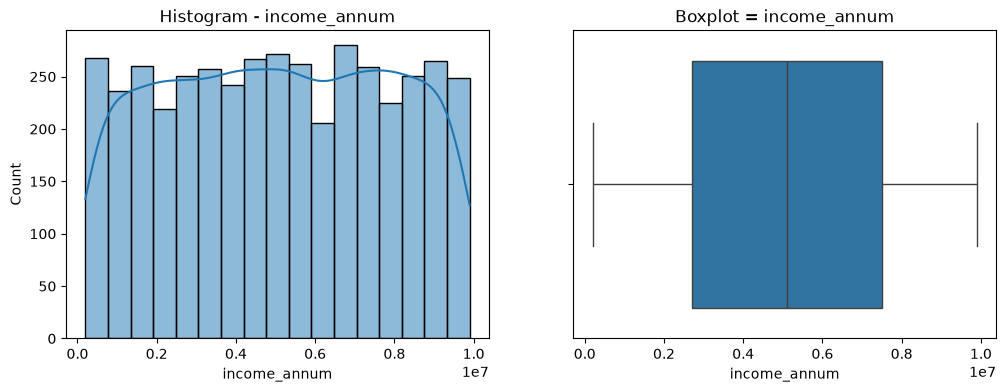

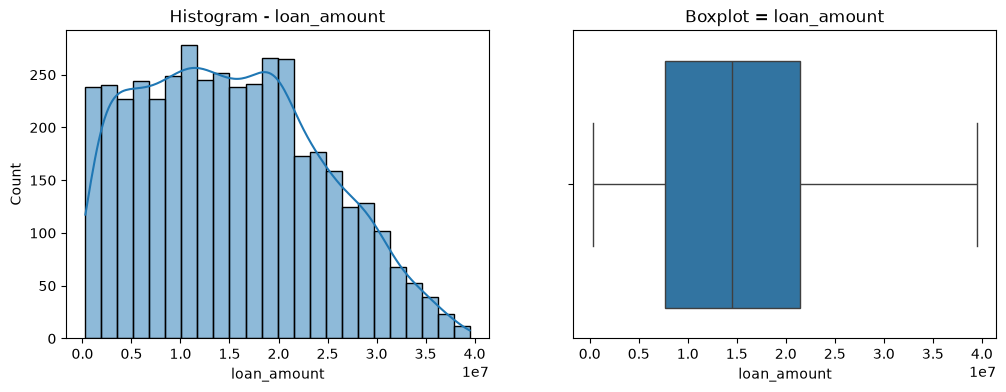

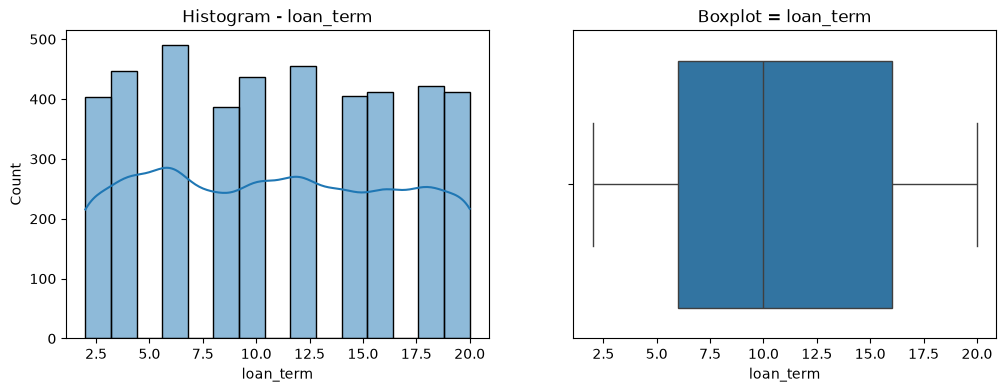

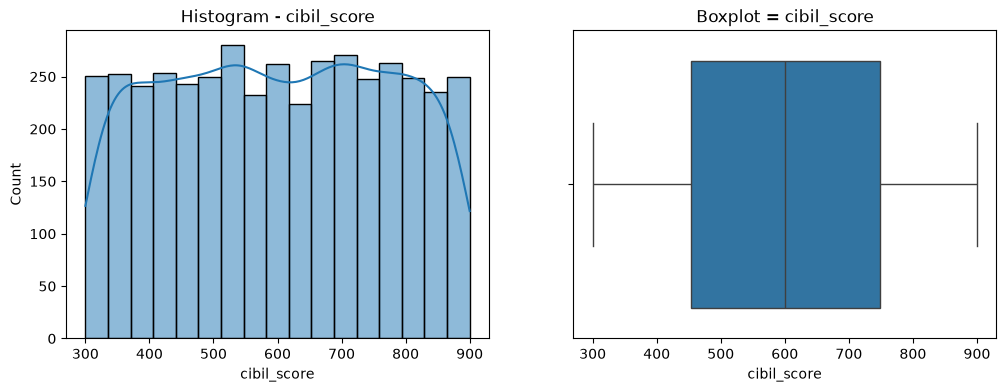

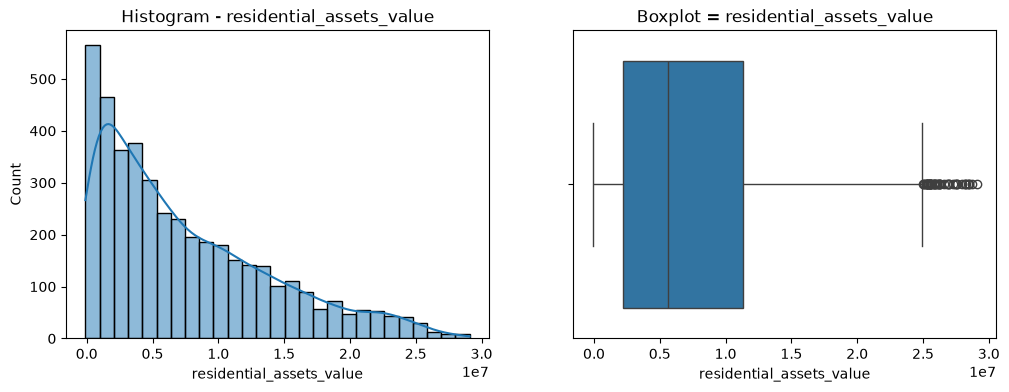

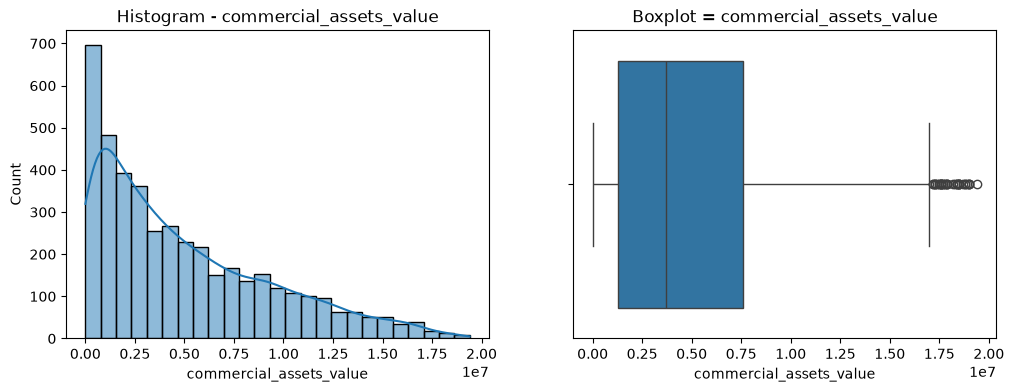

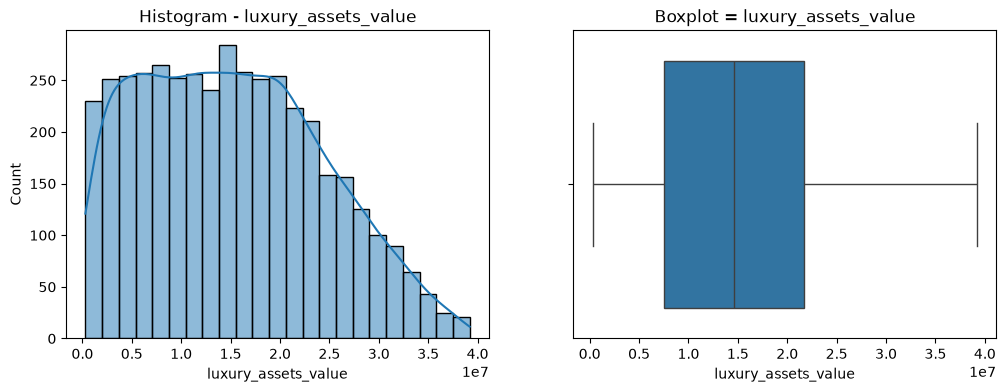

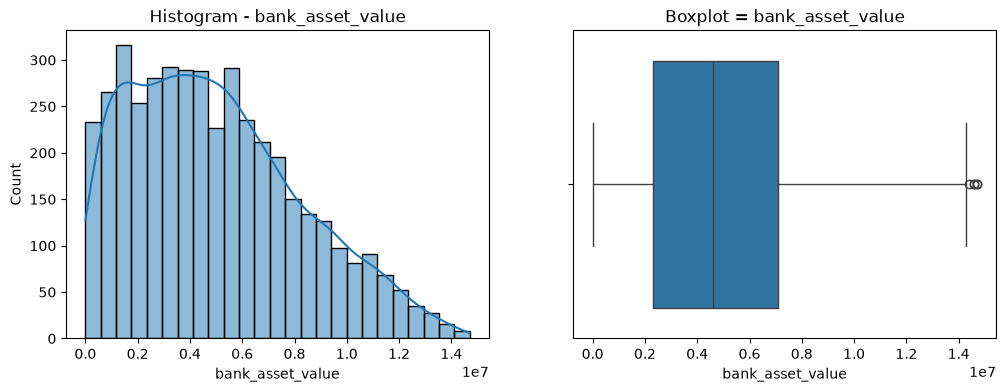

In [20]:
for col in X.columns.tolist():
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    sns.histplot(X[col], kde = True, ax = ax[0])
    ax[0].set_title(f'Histogram - {col}')
    sns.boxplot(x = X[col], ax = ax[1])
    ax[1].set_title(f'Boxplot = {col}')
    plt.show()

In [21]:
std_scaler = ['no_of_dependents', 'income_annum', 'loan_amount', 'cibil_score', 'luxury_assets_value', 'loan_term']

In [22]:
pow_transform = ['residential_assets_value', 'commercial_assets_value', 'bank_asset_value']

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, PowerTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('std', StandardScaler(), std_scaler),
        ('pwr', PowerTransformer(method='yeo-johnson'), pow_transform)
    ],
    remainder='passthrough'
)

In [24]:
y

0       1
1       0
2       0
3       0
4       0
       ..
4264    0
4265    1
4266    0
4267    1
4268    1
Name: loan_status, Length: 4269, dtype: int64

In [25]:
y.value_counts()

loan_status
1    2656
0    1613
Name: count, dtype: int64

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline

In [27]:
models = {
    'KNN' : make_pipeline(preprocessor, KNeighborsClassifier()),
    'Decision Trees' : DecisionTreeClassifier(random_state=42),
    'Gaussian NB' : make_pipeline(preprocessor, GaussianNB()),
    'Bernoulli NB' : BernoulliNB(),
    'SVM' :make_pipeline(preprocessor, SVC(random_state=42))
}

cv_methods = {
    'K-Fold' : StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    'Random Subsampling ' : StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
}

In [28]:
X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [29]:
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.fit_transform(X_test)

In [30]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"================ {name} ================")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=['Rejected (0)', 'Approved (1)']))

================ KNN ================
Accuracy: 0.8981
              precision    recall  f1-score   support

Rejected (0)       0.87      0.86      0.86       323
Approved (1)       0.91      0.92      0.92       531

    accuracy                           0.90       854
   macro avg       0.89      0.89      0.89       854
weighted avg       0.90      0.90      0.90       854

================ Decision Trees ================
Accuracy: 0.9813
              precision    recall  f1-score   support

Rejected (0)       0.98      0.98      0.98       323
Approved (1)       0.98      0.98      0.98       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854

================ Gaussian NB ================
Accuracy: 0.9485
              precision    recall  f1-score   support

Rejected (0)       0.93      0.93      0.93       323
Approved (1)       0.96      0.96      0.96       531

/home/hadrian/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hadrian/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/hadrian/anaconda3/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0]

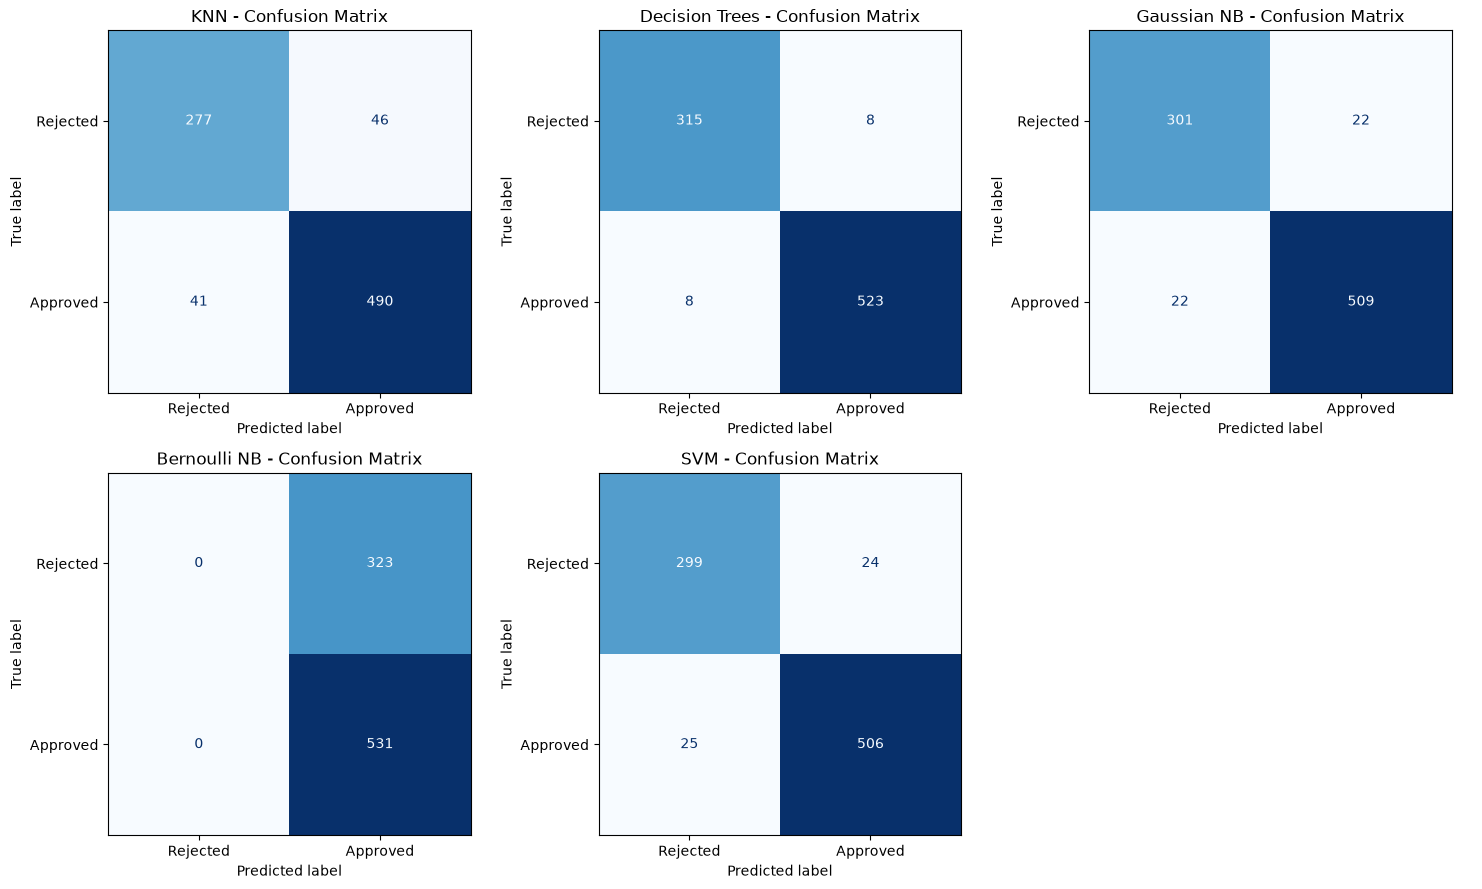

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Rejected', 'Approved'])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name} - Confusion Matrix")

# Hide the unused 6th subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

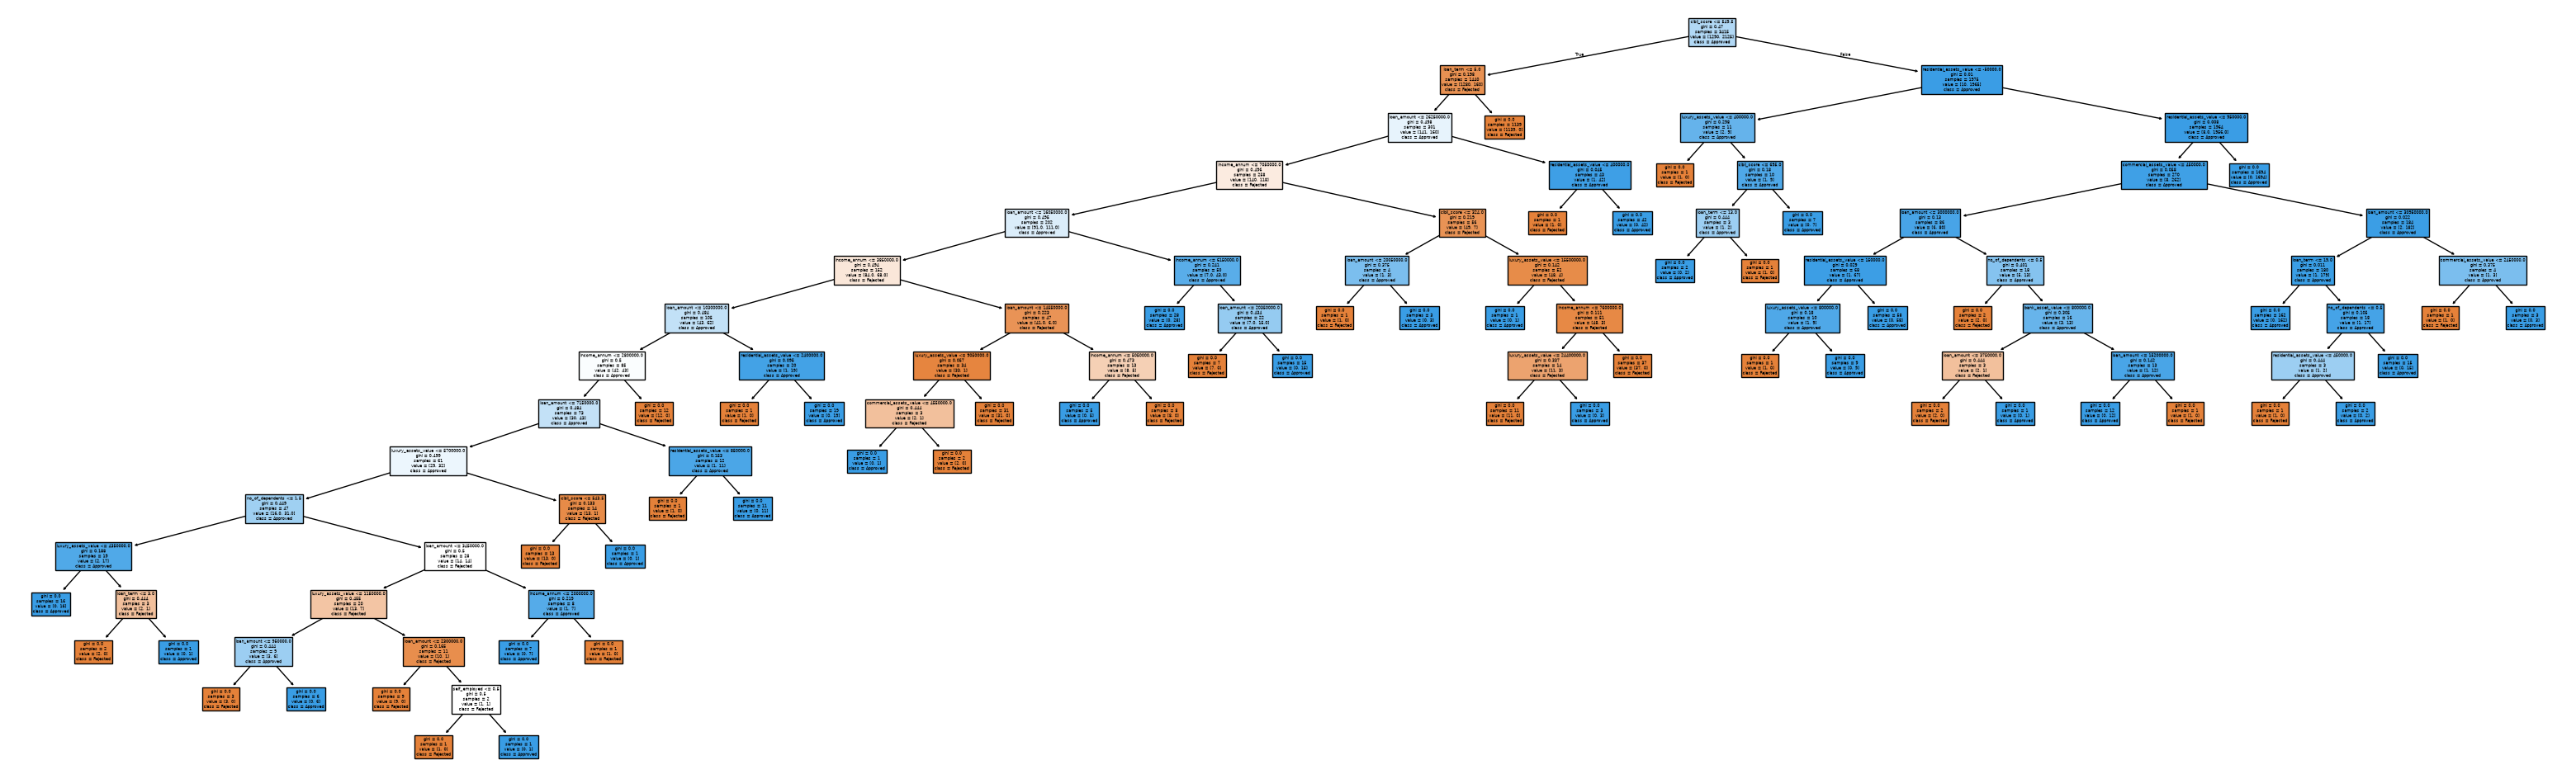

In [37]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(40, 12))
plot_tree(
    models["Decision Trees"],
    feature_names=X.columns,
    class_names=["Rejected", "Approved"],
    filled=True,
)
plt.savefig("full_tree.png", dpi=300, bbox_inches="tight")
plt.show()

